# Лабораторная работа 2

Белдинова М.С., группа 6233, вариант 4 (набор данных MNIST)

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import time
from math import sqrt, ceil
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

Вспомогательные функции: численный градиент (для проверки backprop) и вывод весов в виде сетки картинок.

In [2]:
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
    """численный градиент f в точке x (центральная разность по каждой координате)"""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h
        fxph = f(x)
        x[ix] = oldval - h
        fxmh = f(x)
        x[ix] = oldval

        grad[ix] = (fxph - fxmh) / (2 * h)
        if verbose:
            print(ix, grad[ix])
        it.iternext()
    return grad


def visualize_grid(Xs, ubound=255.0, padding=1):
    """Xs: (N, H, W, C) -> одна картинка-сетка, каждое изображение нормируется в [0, ubound]"""
    (N, H, W, C) = Xs.shape
    grid_size = int(ceil(sqrt(N)))
    grid_height = H * grid_size + padding * (grid_size - 1)
    grid_width = W * grid_size + padding * (grid_size - 1)
    grid = np.zeros((grid_height, grid_width, C))
    next_idx = 0
    y0, y1 = 0, H
    for y in range(grid_size):
        x0, x1 = 0, W
        for x in range(grid_size):
            if next_idx < N:
                img = Xs[next_idx]
                low, high = np.min(img), np.max(img)
                grid[y0:y1, x0:x1] = ubound * (img - low) / max(high - low, 1e-12)
                next_idx += 1
            x0 += W + padding
            x1 += W + padding
        y0 += H + padding
        y1 += H + padding
    return grid

1. Реализация класса TwoLayerNet.

Архитектура: вход - полносвязный слой - ReLU - полносвязный слой - softmax. Функция потерь - кросс-энтропия + L2-регуляризация весов $reg\cdot(\|W_1\|^2 + \|W_2\|^2)$.

In [3]:
class TwoLayerNet(object):
    """
    Двухслойная полносвязная сеть: N входов размерности D, скрытый слой из H нейронов, C классов.
    input - fully connected layer - ReLU - fully connected layer - softmax
    """

    def __init__(self, input_size, hidden_size, output_size, std=1e-4):
        # веса - маленькие случайные числа, смещения - нули
        self.params = {}
        self.params['W1'] = std * np.random.randn(input_size, hidden_size)
        self.params['b1'] = np.zeros(hidden_size)
        self.params['W2'] = std * np.random.randn(hidden_size, output_size)
        self.params['b2'] = np.zeros(output_size)

    def loss(self, X, y=None, reg=0.0):
        """
        Если y не передан - возвращает оценки классов scores (N, C).
        Иначе возвращает (loss, grads), grads - словарь градиентов по всем параметрам.
        """
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        N, D = X.shape

        # прямой проход
        z1 = X.dot(W1) + b1
        h1 = np.maximum(0, z1)
        scores = h1.dot(W2) + b2

        if y is None:
            return scores

        # softmax + cross-entropy
        shifted = scores - np.max(scores, axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
        loss = -np.sum(np.log(probs[np.arange(N), y])) / N
        loss += reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        # обратный проход
        grads = {}
        dscores = probs.copy()
        dscores[np.arange(N), y] -= 1
        dscores /= N

        grads['W2'] = h1.T.dot(dscores) + 2 * reg * W2
        grads['b2'] = np.sum(dscores, axis=0)

        dh1 = dscores.dot(W2.T)
        dz1 = dh1 * (z1 > 0)       # производная ReLU
        grads['W1'] = X.T.dot(dz1) + 2 * reg * W1
        grads['b1'] = np.sum(dz1, axis=0)

        return loss, grads

    def train(self, X, y, X_val, y_val,
              learning_rate=1e-3, learning_rate_decay=0.95,
              reg=5e-6, num_iters=100,
              batch_size=200, verbose=False):
        """
        Обучение стохастическим градиентным спуском.
        X, y - обучающая выборка; X_val, y_val - валидационная (для контроля accuracy)
        learning_rate - начальный шаг SGD
        learning_rate_decay - множитель, на который шаг уменьшается после каждой эпохи
        reg - коэффициент L2-регуляризации
        num_iters - количество шагов оптимизации
        batch_size - число объектов в мини-батче
        verbose - печатать ли loss по ходу обучения
        """
        num_train = X.shape[0]
        iterations_per_epoch = max(num_train // batch_size, 1)

        loss_history = []
        train_acc_history = []
        val_acc_history = []

        for it in range(num_iters):
            batch_idx = np.random.choice(num_train, batch_size, replace=True)
            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            loss, grads = self.loss(X_batch, y=y_batch, reg=reg)
            loss_history.append(loss)

            for name in self.params:
                self.params[name] -= learning_rate * grads[name]

            if verbose and it % 100 == 0:
                print('iteration %d / %d: loss %f' % (it, num_iters, loss))

            # раз в эпоху считаем accuracy и уменьшаем шаг
            if it % iterations_per_epoch == 0:
                train_acc = (self.predict(X_batch) == y_batch).mean()
                val_acc = (self.predict(X_val) == y_val).mean()
                train_acc_history.append(train_acc)
                val_acc_history.append(val_acc)
                learning_rate *= learning_rate_decay

        return {
            'loss_history': loss_history,
            'train_acc_history': train_acc_history,
            'val_acc_history': val_acc_history,
        }

    def predict(self, X):
        scores = self.loss(X)
        return np.argmax(scores, axis=1)

Проверка реализации на модельных данных.

In [4]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Сравнение выхода сети с эталонными значениями. Ошибка должна быть < 1e-7.

In [5]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()

print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08


# Прямой проход: вычисление loss

Ошибка должна быть < 1e-12.

In [6]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
1.7985612998927536e-13


# Обратный проход

Проверка аналитических градиентов численными. Ошибка должна быть < 1e-8 для W1, W2, b1, b2.

In [7]:
loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447625e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738421e-09


# Обучение нейронной сети на смоделированных данных

Обучаем, пока loss не станет < 0.02.

Final training loss:  0.017149607938732093


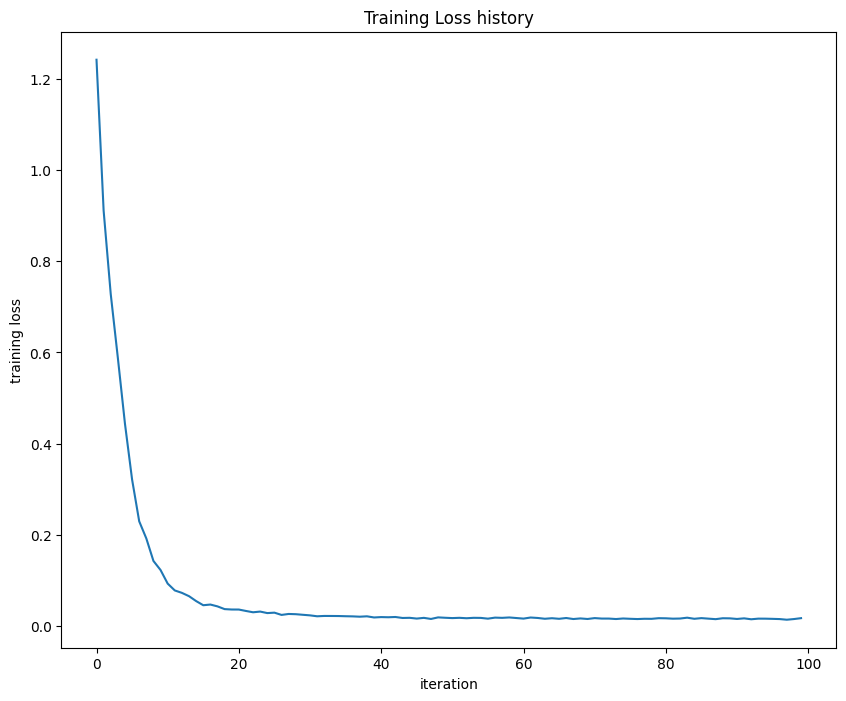

In [8]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])

plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (MNIST)

Загрузка данных (sklearn `load_digits`, изображения 8x8), разбиение на обучающую / валидационную / тестовую выборки и предобработка как в ЛР 1 (вычитание среднего изображения).

In [9]:
digits = load_digits()
X_all = digits.images.reshape(len(digits.images), -1).astype(np.float64)
y_all = digits.target.astype(np.int64)

perm = np.random.RandomState(0).permutation(X_all.shape[0])
X_all, y_all = X_all[perm], y_all[perm]

num_test, num_val = 360, 180
X_test, y_test = X_all[:num_test], y_all[:num_test]
X_val, y_val = X_all[num_test:num_test + num_val], y_all[num_test:num_test + num_val]
X_train, y_train = X_all[num_test + num_val:], y_all[num_test + num_val:]

mean_image = np.mean(X_train, axis=0)
X_train = X_train - mean_image
X_val = X_val - mean_image
X_test = X_test - mean_image

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Train data shape:  (1257, 64)
Train labels shape:  (1257,)
Validation data shape:  (180, 64)
Validation labels shape:  (180,)
Test data shape:  (360, 64)
Test labels shape:  (360,)


Обучение сети с параметрами по умолчанию (из шаблона, только размер входа заменен на 8 * 8 = 64).

Параметры метода train:
- `X, y` - обучающая выборка и метки;
- `X_val, y_val` - валидационная выборка, на ней раз в эпоху считается accuracy, в обучении она не участвует;
- `num_iters` - число шагов градиентного спуска (одна итерация - один мини-батч);
- `batch_size` - размер мини-батча, по которому оценивается градиент;
- `learning_rate` - шаг градиентного спуска;
- `learning_rate_decay` - после каждой эпохи шаг умножается на этот коэффициент (постепенное уменьшение шага);
- `reg` - сила L2-регуляризации весов, штраф за большие веса (борьба с переобучением);
- `verbose` - вывод значения loss каждые 100 итераций.

In [10]:
np.random.seed(0)
input_size = 8 * 8
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-4, learning_rate_decay=0.95,
            reg=0.25, verbose=True)

val_acc = (net.predict(X_val) == y_val).mean()
print('Validation accuracy: ', val_acc)

iteration 0 / 1000: loss 2.302594
iteration 100 / 1000: loss 2.302591


iteration 200 / 1000: loss 2.302591
iteration 300 / 1000: loss 2.302587


iteration 400 / 1000: loss 2.302591
iteration 500 / 1000: loss 2.302592


iteration 600 / 1000: loss 2.302589
iteration 700 / 1000: loss 2.302597


iteration 800 / 1000: loss 2.302597
iteration 900 / 1000: loss 2.302594


Validation accuracy:  0.1


Графики loss и accuracy для обучения с параметрами по умолчанию.

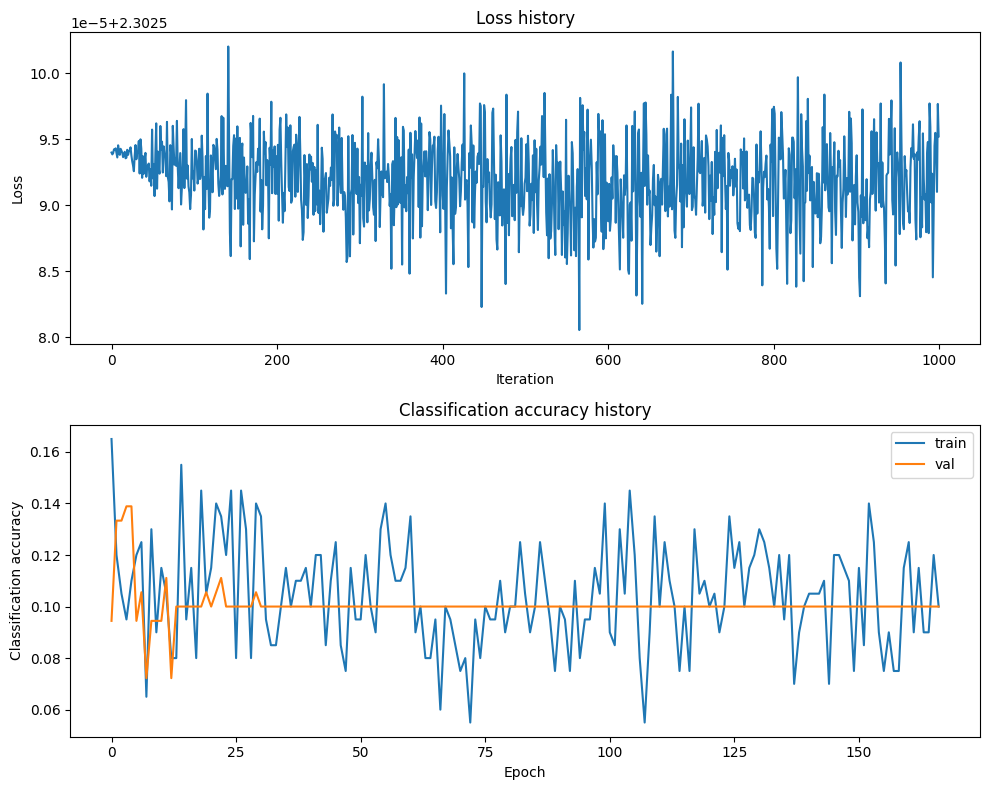

In [11]:
def plot_stats(stats):
    plt.subplot(2, 1, 1)
    plt.plot(stats['loss_history'])
    plt.title('Loss history')
    plt.xlabel('Iteration')
    plt.ylabel('Loss')

    plt.subplot(2, 1, 2)
    plt.plot(stats['train_acc_history'], label='train')
    plt.plot(stats['val_acc_history'], label='val')
    plt.title('Classification accuracy history')
    plt.xlabel('Epoch')
    plt.ylabel('Classification accuracy')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_stats(stats)

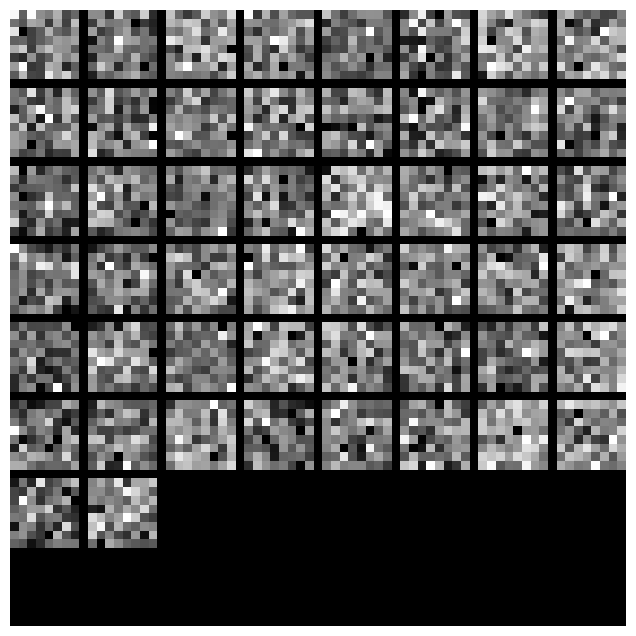

In [12]:
def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(8, 8, 1, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=1).astype('uint8').squeeze(), cmap='gray')
    plt.gca().axis('off')
    plt.show()

show_net_weights(net)

С параметрами по умолчанию сеть почти не обучается: при std = 1e-4 начальные веса очень маленькие, а шаг 1e-4 слишком мал для 64 признаков со значениями порядка единиц, loss за 1000 итераций падает слабо. Веса первого слоя на картинке выше похожи на шум.

## Настройка гиперпараметров

Перебираем размер скрытого слоя, шаг обучения, коэффициент уменьшения шага и регуляризацию (3000 итераций).

Важный момент для нашего набора: в обучающей выборке всего 1257 изображений, при batch_size = 200 эпоха - это 6 итераций, и шаг уменьшается в 0.95 раза каждые 6 итераций. За 3000 итераций он уменьшится в 0.95^500 ~ 1e-11 раз, то есть обучение фактически останавливается в самом начале. Поэтому learning_rate_decay тоже включен в перебор. Модель выбирается по accuracy на валидационной выборке, тестовая выборка используется только один раз для итоговой оценки.

In [13]:
hidden_sizes = [50, 100, 200]
learning_rates = [3e-3, 1e-2, 3e-2]
lr_decays = [0.95, 0.99, 1.0]
regs = [1e-3, 1e-2]
num_iters = 3000

results = {}
best_val = -1
best_net = None
best_stats = None
best_params = None

tic = time.time()
for hs in hidden_sizes:
    for lr in learning_rates:
        for reg in regs:
            for dec in lr_decays:
                np.random.seed(1)
                net = TwoLayerNet(input_size, hs, num_classes, std=1e-2)
                st = net.train(X_train, y_train, X_val, y_val,
                               num_iters=num_iters, batch_size=200,
                               learning_rate=lr, learning_rate_decay=dec,
                               reg=reg, verbose=False)
                train_acc = (net.predict(X_train) == y_train).mean()
                val_acc = (net.predict(X_val) == y_val).mean()
                results[(hs, lr, reg, dec)] = (train_acc, val_acc)
                if val_acc > best_val:
                    best_val, best_net, best_stats = val_acc, net, st
                    best_params = (hs, lr, reg, dec)
print('Перебор занял %.1f c' % (time.time() - tic))

for key in sorted(results):
    hs, lr, reg, dec = key
    print('hidden %3d  lr %.0e  reg %.0e  decay %.2f   train acc: %.4f  val acc: %.4f'
          % (hs, lr, reg, dec, *results[key]))

print()
print('Лучшие параметры (hidden, lr, reg, decay):', best_params)
print('best validation accuracy: %.4f' % best_val)

Перебор занял 420.1 c
hidden  50  lr 3e-03  reg 1e-03  decay 0.95   train acc: 0.6078  val acc: 0.5556
hidden  50  lr 3e-03  reg 1e-03  decay 0.99   train acc: 0.8528  val acc: 0.8000
hidden  50  lr 3e-03  reg 1e-03  decay 1.00   train acc: 0.9841  val acc: 0.9611
hidden  50  lr 3e-03  reg 1e-02  decay 0.95   train acc: 0.6086  val acc: 0.5556
hidden  50  lr 3e-03  reg 1e-02  decay 0.99   train acc: 0.8504  val acc: 0.8000
hidden  50  lr 3e-03  reg 1e-02  decay 1.00   train acc: 0.9841  val acc: 0.9556
hidden  50  lr 1e-02  reg 1e-03  decay 0.95   train acc: 0.7176  val acc: 0.6556
hidden  50  lr 1e-02  reg 1e-03  decay 0.99   train acc: 0.9761  val acc: 0.9500
hidden  50  lr 1e-02  reg 1e-03  decay 1.00   train acc: 0.9992  val acc: 0.9667
hidden  50  lr 1e-02  reg 1e-02  decay 0.95   train acc: 0.7136  val acc: 0.6556
hidden  50  lr 1e-02  reg 1e-02  decay 0.99   train acc: 0.9745  val acc: 0.9444
hidden  50  lr 1e-02  reg 1e-02  decay 1.00   train acc: 0.9976  val acc: 0.9722
hidden

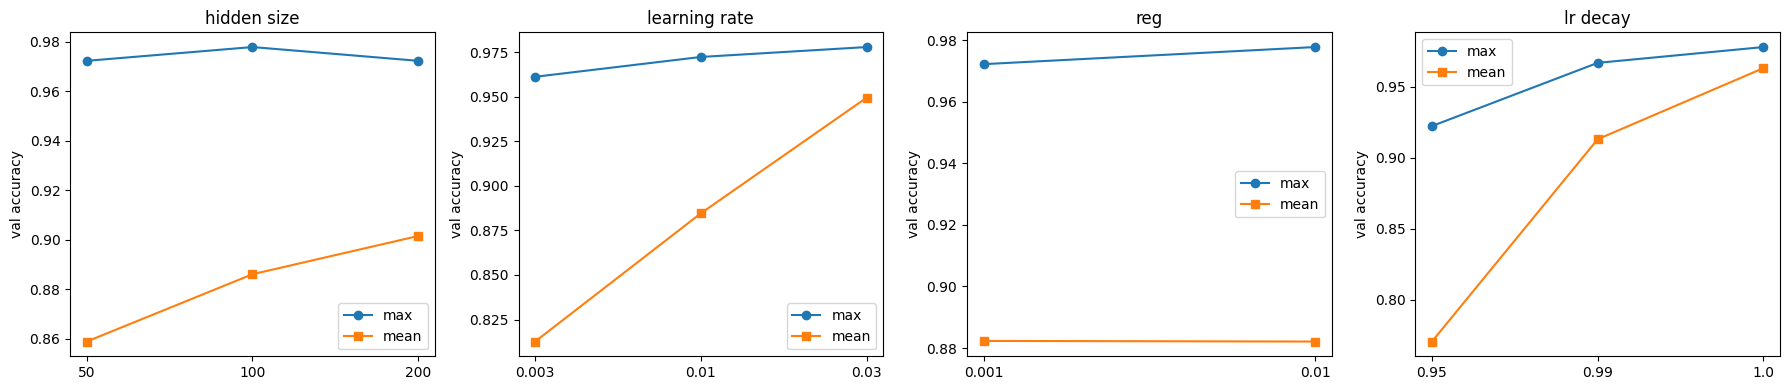

In [14]:
# влияние отдельных гиперпараметров: лучшая val accuracy при фиксированном значении
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (pos, name, values) in zip(axes, [(0, 'hidden size', hidden_sizes), (1, 'learning rate', learning_rates),
                                         (2, 'reg', regs), (3, 'lr decay', lr_decays)]):
    best_for_value = [max(v[1] for k, v in results.items() if k[pos] == val) for val in values]
    mean_for_value = [np.mean([v[1] for k, v in results.items() if k[pos] == val]) for val in values]
    ax.plot(range(len(values)), best_for_value, '-o', label='max')
    ax.plot(range(len(values)), mean_for_value, '-s', label='mean')
    ax.set_xticks(range(len(values)))
    ax.set_xticklabels([str(v) for v in values])
    ax.set_title(name)
    ax.set_ylabel('val accuracy')
    ax.legend()
plt.tight_layout()
plt.show()

Графики обучения и веса первого слоя для лучшей сети.

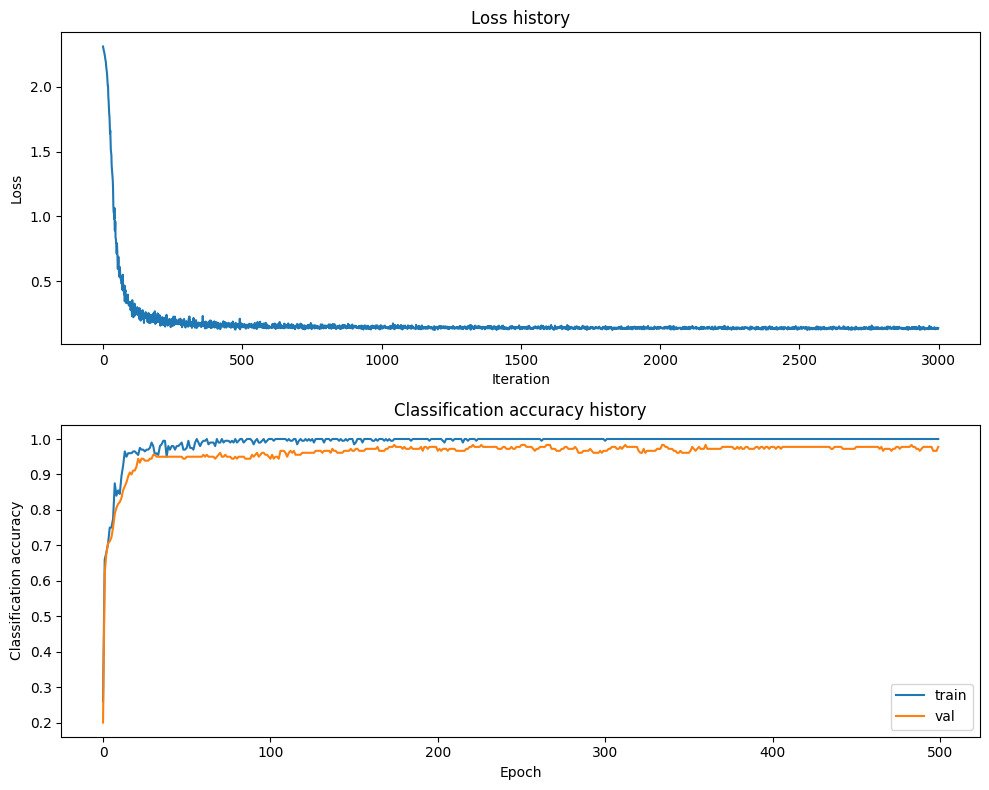

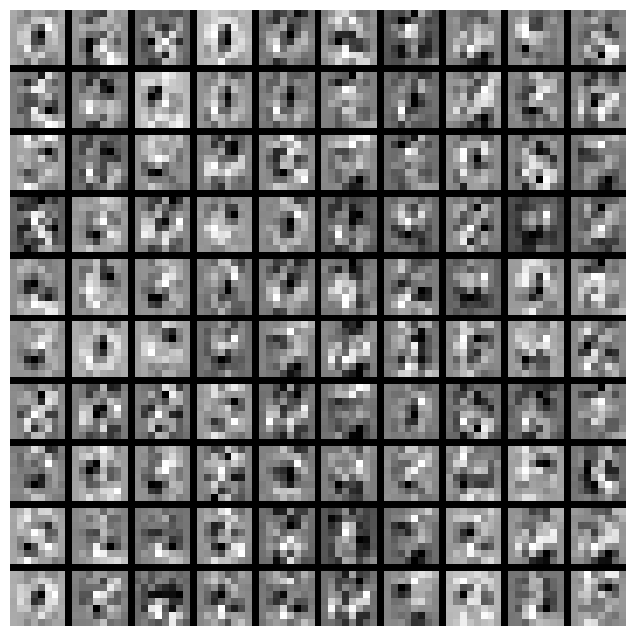

In [15]:
plot_stats(best_stats)
show_net_weights(best_net)

### Дополнительный эксперимент: сокращение размерности (PCA)

Проецируем данные на первые k главных компонент (по обучающей выборке) и обучаем ту же сеть на сжатом представлении.

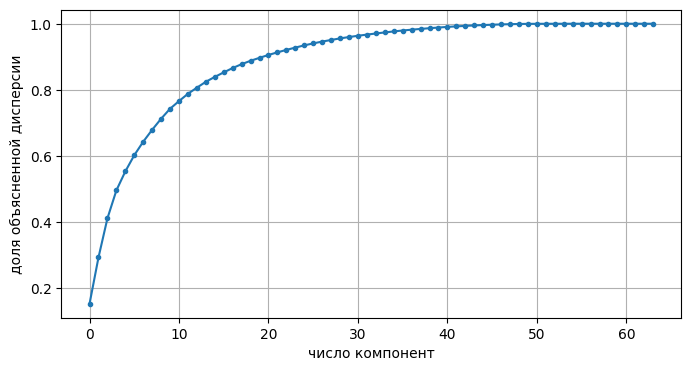

PCA 10 компонент (74.3% дисперсии): val accuracy = 0.9333


PCA 20 компонент (89.7% дисперсии): val accuracy = 0.9722


PCA 30 компонент (96.0% дисперсии): val accuracy = 0.9778


PCA 40 компонент (98.8% дисперсии): val accuracy = 0.9722


PCA 64 компонент (100.0% дисперсии): val accuracy = 0.9611


In [16]:
# PCA через SVD центрированной обучающей выборки (данные уже центрированы)
U, S, Vt = np.linalg.svd(X_train, full_matrices=False)
explained = (S ** 2) / np.sum(S ** 2)

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(explained), '-o', markersize=3)
plt.xlabel('число компонент')
plt.ylabel('доля объясненной дисперсии')
plt.grid(True)
plt.show()

hs, lr, reg, dec = best_params
pca_results = {}
for n_comp in [10, 20, 30, 40, 64]:
    P = Vt[:n_comp].T
    Xtr_p, Xv_p = X_train.dot(P), X_val.dot(P)
    np.random.seed(1)
    net_p = TwoLayerNet(n_comp, hs, num_classes, std=1e-2)
    net_p.train(Xtr_p, y_train, Xv_p, y_val, num_iters=num_iters, batch_size=200,
                learning_rate=lr, learning_rate_decay=dec, reg=reg)
    pca_results[n_comp] = (net_p.predict(Xv_p) == y_val).mean()
    print('PCA %2d компонент (%.1f%% дисперсии): val accuracy = %.4f'
          % (n_comp, 100 * np.sum(explained[:n_comp]), pca_results[n_comp]))

Итоговая оценка лучшей модели на тестовой выборке.

In [17]:
test_acc = (best_net.predict(X_test) == y_test).mean()
print('Лучшая модель: hidden=%d, lr=%g, reg=%g, decay=%g, iters=%d' % (best_params + (num_iters,)))
print('Validation accuracy: %.4f' % best_val)
print('Test accuracy: %.4f' % test_acc)

Лучшая модель: hidden=100, lr=0.03, reg=0.01, decay=1, iters=3000
Validation accuracy: 0.9778
Test accuracy: 0.9722


Выводы по результатам работы.

**Выводы:**

1. Реализована двухслойная полносвязная сеть (affine - ReLU - affine - softmax) с прямым и обратным проходом. Проверка на модельных данных: отличие выхода сети от эталона ~4e-8, отличие loss ~2e-13, относительная ошибка градиентов по сравнению с численными не больше 4e-9. На модельных данных за 100 итераций loss опускается до 0.017 (< 0.02).
2. С параметрами по умолчанию из шаблона (std = 1e-4, lr = 1e-4, decay = 0.95) сеть на нашем наборе не обучается: loss остается 2.3026, val accuracy 10% (случайное угадывание). Причины: слишком маленькие начальные веса и шаг, а также быстрое уменьшение шага - эпоха у нас всего 6 итераций, и при decay = 0.95 шаг за 1000 итераций уменьшается в тысячи раз.
3. Самым важным гиперпараметром оказался learning_rate_decay: при decay = 0.95 даже хорошие значения шага дают заметно худший результат, лучшие модели получены при decay = 1.0 (без уменьшения шага). Шаг обучения нужен порядка 1e-2 - 3e-2. Размер скрытого слоя (50/100/200) и регуляризация (1e-3/1e-2) влияют слабо.
4. Лучшая модель: hidden = 100, lr = 3e-2, reg = 1e-2, decay = 1.0, 3000 итераций. Validation accuracy 97.8%, **test accuracy 97.2%**. Это лучше линейного softmax-классификатора из ЛР 1 (95.8%) за счет нелинейности (скрытый слой с ReLU).
5. Веса первого слоя обученной сети выглядят как фрагменты цифр (штрихи и дуги), в отличие от шума у необученной сети.
6. Эксперимент с PCA: уже 20-30 главных компонент (90-96% дисперсии) дают ту же точность, что и все 64 признака (97.2-97.8% на валидации), а при 10 компонентах точность падает до 93.3%. Значит, в изображениях 8x8 много избыточной информации, и размерность можно уменьшить примерно вдвое без потери качества.